## **Praktikum Sistem Komunikasi Multimedia/Sistem dan Teknologi Multimedia**



---



* Nama: Cantika Angela Putri
* NIM: 221331004
* Kelas: 3A - TTE


## Modul 9: LZ78 - Bagian Decoder

# Instruksi!

Sebelum melakukan pekerjaan di bawah, ada beberapa hal yang harus diperhatikan.

* Waktu pengerjaan sesuai dengan deadline pada GCR.
* GCR akan ditutup setelah jam tersebut.
* Waktu submit ke GCR berpengaruh pada nilai, lebih cepat akan mendapat nilai tambahan.
* Jika ada kendala saat upload file ipynb, maka bisa dengan menyematkan link google collabnya pada kolom submission tugas di GCR.
* Jika ada pertanyaan bisa diajukan di grup perkuliahan.

*selamat mengerjakan*

### Pendahuluan

**Pendahuluan**   

LZ78 adalah sebuah metode kompresi data yang dikembangkan oleh Abraham Lempel dan Jacob Ziv pada tahun 1978. Nama LZ78 berasal dari inisial kedua penemu tersebut dan tahun penemuan. Metode ini merupakan salah satu dari sejumlah algoritma kompresi data yang dikenal sebagai algoritma LZ (Lempel-Ziv).

Konsep dasar dari LZ78 adalah menggantikan pola-pola data yang sering muncul dengan simbol-simbol yang lebih pendek. Algoritma ini memanfaatkan kamus atau tabel untuk menyimpan dan mengelola pola-pola yang telah muncul sebelumnya selama proses kompresi. Setiap kali sebuah pola baru ditemukan, algoritma menyimpan pola tersebut dalam kamus dan menggantinya dengan sebuah simbol yang lebih pendek.

Proses kompresi LZ78 melibatkan dua tindakan utama: pencarian kamus untuk menemukan pola yang cocok dan menambahkan pola baru ke dalam kamus. Informasi mengenai pola-pola tersebut kemudian dijadikan sebagai referensi untuk menggantikan pola-pola serupa yang muncul selama proses kompresi.

Meskipun LZ78 merupakan salah satu metode kompresi yang cukup efisien, terdapat berbagai varian dan pengembangan lebih lanjut seperti LZ77 yang juga populer dalam implementasi kompresi data.

Encode (i.e., compress) data stream BABAABRRRA menggunakan algoritma LZ78.

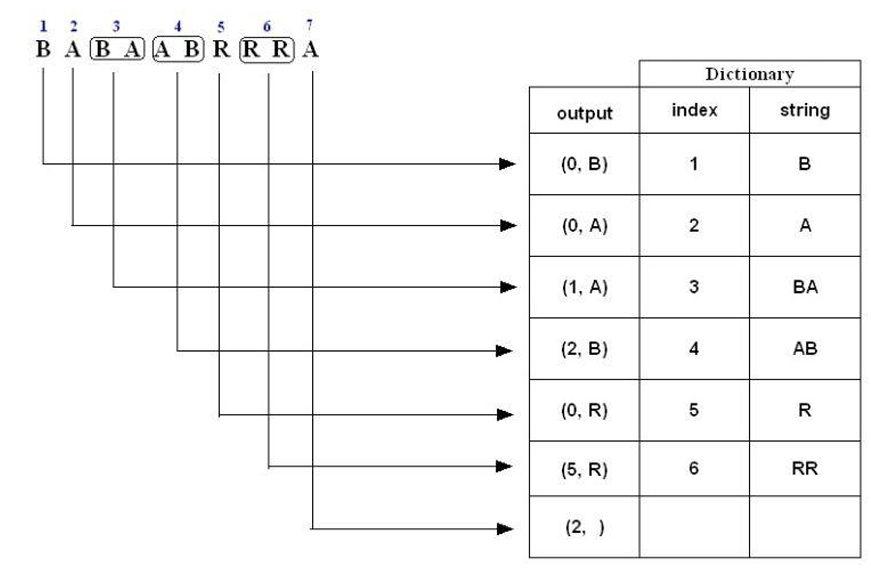

The compressed message is: (0,B)(0,A)(1,A)(2,B)(0,R)(5,R)(2, )

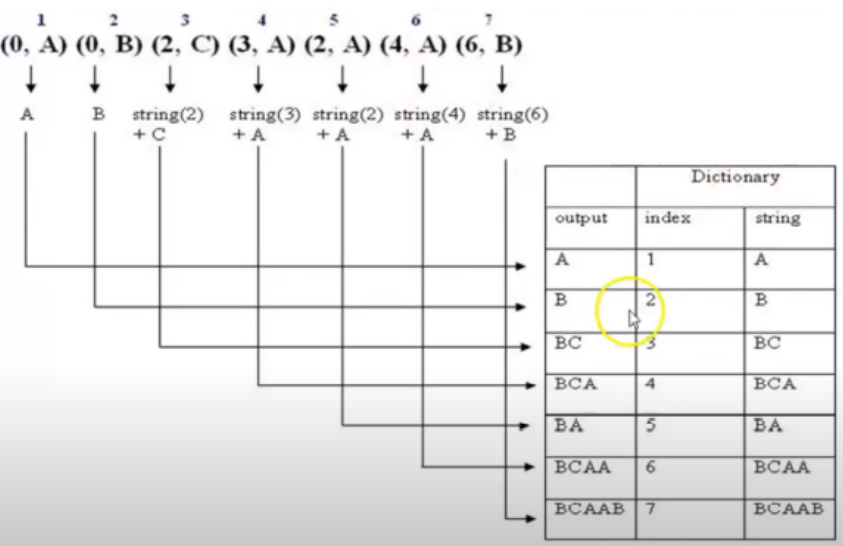

Proses Dekompresi

---

### Langkah-langkah Percobaan

Buatlah program untuk Teknik kompresi LZ78 Bagian Decoder dengan input teks sebagai berikut:
(0,A)(0,B)(2,C)(3,A)(2,A)(4,A)(6,B)

Dengan kaidah LZ78 maka hasil dari decodernya adalah:
ABBCBCABABCAABCAAB

Tampilkan juga dictionary yang dihasilkan dari proses LZ78 tersebut.

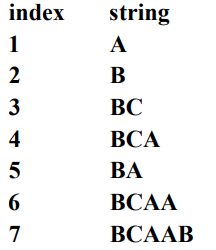



**Instruksi:**





In [7]:
#tuliskan fungsi program pada tiap barisnya

hasilEncode = [(0,'A'),(0,'B'),(2,'C'),(3,'A'),(2,'A'),(4,'A'),(6,'B')]  # Inisialisasi list hasilEncode dengan pasangan (index, karakter)
hasilDecode = ''  # Inisialisasi string hasilDecode kosong untuk menyimpan hasil decoding

dictionary = []  # Inisialisasi list kosong dictionary untuk menyimpan hasil decoding sementara

for i in range(len(hasilEncode)):  # Loop melalui setiap elemen di hasilEncode
  if hasilEncode[i][0] == 0:  # Jika index pada tuple hasilEncode adalah 0
    dictionary.append((i+1,hasilEncode[i][1]))  # Tambahkan elemen baru ke dictionary dengan karakter yang sama

  if hasilEncode[i][0] != 0:  # Jika index pada tuple hasilEncode bukan 0
    index = hasilEncode[i][0]  # Simpan index dari karakter hasilEncode
    dictionary.append((i+1,dictionary[index-1][1]+hasilEncode[i][1]))  # Gabungkan karakter pada index yang ditentukan dengan karakter saat ini dan tambahkan ke dictionary

  hasilDecode = hasilDecode + dictionary[i][1]  # Tambahkan string hasil decoding saat ini ke hasilDecode

print('Hasil Decoder = ' + hasilDecode)  # Cetak hasil decoding akhir
print('Dictionary = ' + str(dictionary))  # Cetak isi dictionary akhir

Hasil Decoder = ABBCBCABABCAABCAAB
Dictionary = [(1, 'A'), (2, 'B'), (3, 'BC'), (4, 'BCA'), (5, 'BA'), (6, 'BCAA'), (7, 'BCAAB')]




> Analisa dari program di atas:

Program ini bertujuan untuk mendekode data dari daftar `hasilEncode`, yang berisi pasangan `(index, karakter)` hasil encoding. Nilai pertama dalam pasangan (`index`) menunjukkan referensi ke elemen sebelumnya, sedangkan nilai kedua (`karakter`) adalah karakter yang akan ditambahkan. Proses dimulai dengan menginisialisasi string kosong `hasilDecode` untuk menyimpan hasil decoding dan daftar `dictionary` untuk merekam elemen-elemen sementara. Program menggunakan loop `for` untuk memproses setiap elemen di `hasilEncode`. Jika indeks bernilai nol, karakter langsung ditambahkan ke `dictionary` sebagai pasangan `(urutan, karakter)`. Jika indeks tidak nol, program mengambil string dari indeks referensi di `dictionary`, menggabungkannya dengan karakter saat ini, lalu menambahkan hasilnya ke `dictionary`.  

Selama proses iterasi, string hasil decoding (`hasilDecode`) diperbarui dengan menambahkan elemen-elemen dari `dictionary` secara bertahap. Setelah seluruh elemen diproses, program mencetak hasil decoding akhir (`hasilDecode`) dan isi lengkap `dictionary`. Dengan logika ini, program merekonstruksi data dari encoding berbasis referensi dengan cara yang efisien, menunjukkan bagaimana data dapat diurai kembali ke bentuk aslinya melalui penggabungan elemen-elemen yang telah didekodekan.



Lampirkan gambar flowchart di bawah ini:

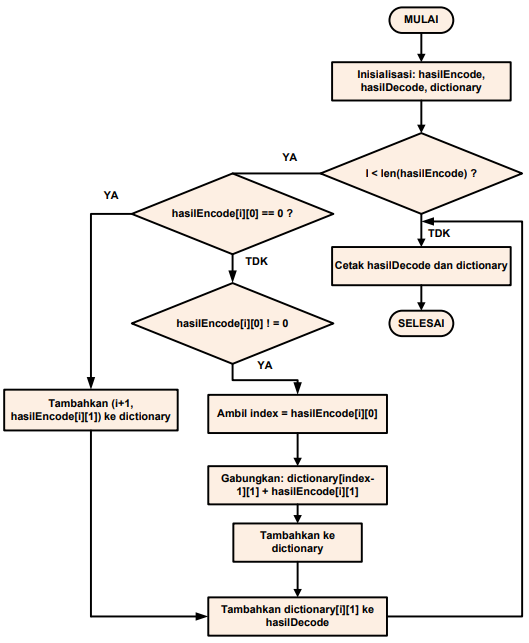

In [11]:
# Fungsi encoding LZ78
def encode_LZ78(data):
    kamus = []
    hasilencode = []
    count = len(data)
    i = 0
    while i < count:
        for j in range(count, i, -1):
            if data[i:j] in kamus:
                getIndex = kamus.index(data[i:j])

                if j == count:
                    kamus.append("")
                    hasilencode.append((getIndex + 1, ""))
                else:
                    kamus.append(data[i:j] + data[j])
                    hasilencode.append((getIndex + 1, data[j]))
                    i = i + len(data[i:j] + data[j]) - 1
                break
            else:
                if len(data[i:j]) == 1:
                    kamus.append(data[i:j])
                    hasilencode.append((0, data[i:j]))
        i = i + 1

    return kamus, hasilencode

# Fungsi decoding LZ78
def decode_LZ78(encoded_data):
    kamus = []
    hasilDecode = ''
    dictionary = []  # Kamus untuk proses decoding

    for i in range(len(hasilEncode)):

      if hasilEncode[i][0] == 0:
        dictionary.append((i+1,hasilEncode[i][1]))

      if hasilEncode[i][0] !=0:
        index = hasilEncode[i][0]
        dictionary.append((i+1,dictionary[index-1][1]+hasilEncode[i][1]))

      hasilDecode = hasilDecode+dictionary[i][1]

    return hasilDecode, dictionary

# Main Program
data_input = 'BABAABRRRA'

kamus_encode, output_LZ78_encode = encode_LZ78(data_input)
print("Kamus hasil encode:", kamus_encode)
print("Hasil encode:", output_LZ78_encode)

output_LZ78_decode, dictionary = decode_LZ78(output_LZ78_encode)
print("Hasil decode:", output_LZ78_decode)
print("Dictionary:", dictionary)

Kamus hasil encode: ['B', 'A', 'BA', 'AB', 'R', 'RR', '']
Hasil encode: [(0, 'B'), (0, 'A'), (1, 'A'), (2, 'B'), (0, 'R'), (5, 'R'), (2, '')]
Hasil decode: BABAABRRRA
Dictionary: [(1, 'B'), (2, 'A'), (3, 'BA'), (4, 'AB'), (5, 'R'), (6, 'RR'), (7, 'A')]




> Analisa dari hasil program decode:

1. Pada percobaan pertama, hasil salin-tempel dari program decode ke program yang telah disediakan menyebabkan error pada bagian penambahan dictionary dalam proses decode, sehingga program tidak dapat dijalankan. Untuk memperbaiki masalah ini, ubah "None" menjadi "" (tanda kutip dua) agar data tersebut dianggap sebagai indeks kosong, sehingga proses decode dapat berjalan dengan baik.

2. Pada proses decoding, terdapat kemungkinan simbol tambahan pada pasangan (indeks, simbol) adalah nilai kosong. Jika nilai tersebut diinterpretasikan sebagai None, program akan gagal karena Python tidak dapat melakukan operasi penambahan string dengan None.





---




© Prof. Hertog Nugroho & Muhammad Yusuf Fadhlan, SST., M.Sc.

Politeknik Negeri Bandung (2023)